In [12]:
#mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

#path to the PlantVillage dataset
data_dir = '/content/drive/MyDrive/PlantVillage'

#install split-folders to organize dataset
!pip install split-folders

import splitfolders

#split into train (70%), val (20%), test (10%)
output_dir = '/content/plantvillage_split'
splitfolders.ratio(data_dir, output=output_dir, seed=42, ratio=(0.7, 0.2, 0.1))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Copying files: 20656 files [01:10, 293.73 files/s]


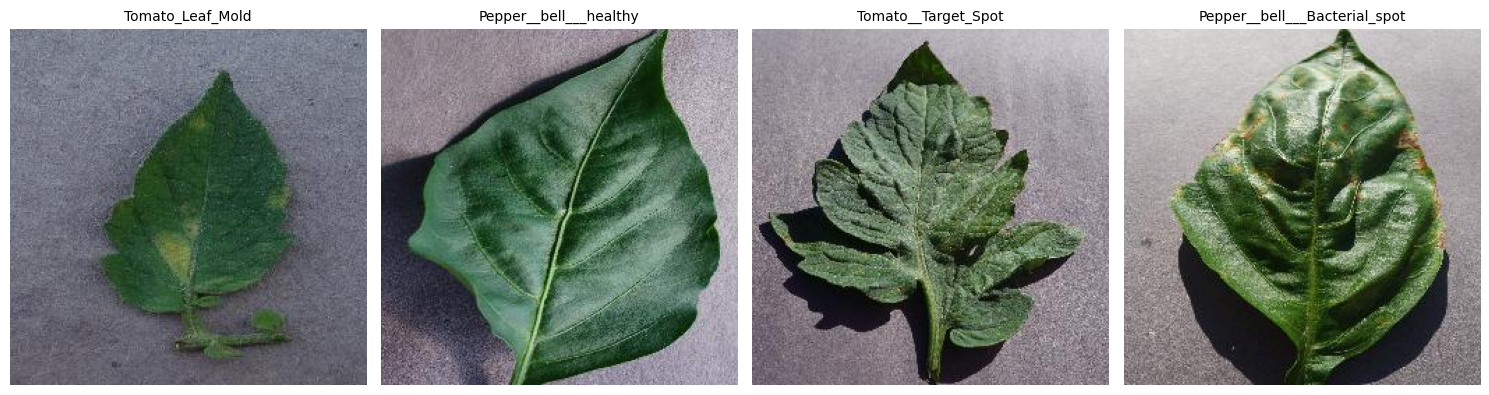

In [13]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import random

#path to the training directory
train_dir = os.path.join(output_dir, 'train')

#get all the plant folder names
classes = [c for c in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, c))]

#set up a grid to show 4 sample images
fig, axes = plt.subplots(1, 4, figsize=(15, 5))

for i in range(4):
    #pick a random class
    random_class = random.choice(classes)
    class_path = os.path.join(train_dir, random_class)

    #pick a random image from that class
    random_img_name = random.choice(os.listdir(class_path))
    img_path = os.path.join(class_path, random_img_name)

    #open and display the image
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(random_class, fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.show()


In [14]:
import tensorflow as tf

img_size = (224, 224)
batch_size = 32

#load the folders into TensorFlow datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    output_dir + "/train",
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    output_dir + "/val",
    image_size=img_size,
    batch_size=batch_size
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    output_dir + "/test",
    image_size=img_size,
    batch_size=batch_size
)

Found 14452 files belonging to 15 classes.
Found 4125 files belonging to 15 classes.
Found 2078 files belonging to 15 classes.


In [15]:
from tensorflow.keras import layers

#define data augmentation (only for training dataset)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

#define normalization (for all datasets i.e. train, val, test)
normalization_layer = layers.Rescaling(1./255)

#apply to each dataset
train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y))
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))

val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

#optimize dataset speed in memory
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)


In [16]:
from tensorflow.keras import models

#get the number of plant classes
train_dir = output_dir + "/train"
class_names = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))])
num_classes = len(class_names)
print(f"Successfully found {num_classes} plant classes.")

#design basic CNN model
model_scratch = models.Sequential([
    #input layer (224x224 images with 3 color channels)
    layers.Input(shape=(224, 224, 3)),

    #first convolutional block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    #second convolutional block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    #third convolutional block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    #flatten spatial maps to a 1D vector
    layers.Flatten(),

    #final classification layer
    layers.Dense(num_classes, activation='softmax')
])

#complie model
model_scratch.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#display the layout of your custom scratch CNN
model_scratch.summary()

#train scratch CNN model
print("Starting training for the basic scratch model...")
history_scratch = model_scratch.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Successfully found 15 plant classes.


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 15)             │     1,297,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,391,183 (5.31 MB)

 Trainable params: 1,391,183 (5.31 MB)

 Non-trainable params: 0 (0.00 B)

Starting training for the basic scratch model...
Epoch 1/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 200s 435ms/step - accuracy: 0.6135 - loss: 1.2141 - val_accuracy: 0.7282 - val_loss: 0.8967
Epoch 2/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 180s 397ms/step - accuracy: 0.7885 - loss: 0.6330 - val_accuracy: 0.7632 - val_loss: 0.8349
Epoch 3/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 178s 393ms/step - accuracy: 0.8288 - loss: 0.5084 - val_accuracy: 0.8119 - val_loss: 0.6371
Epoch 4/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 180s 399ms/step - accuracy: 0.8505 - loss: 0.4530 - val_accuracy: 0.7903 - val_loss: 0.6799
Epoch 5/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 179s 396ms/step - accuracy: 0.8791 - loss: 0.3683 - val_accuracy: 0.7445 - val_loss: 1.1040
Epoch 6/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 180s 397ms/step - accuracy: 0.8878 - loss: 0.3349 - val_accuracy: 0.8175 - val_loss: 0.6436
Epoch 7/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 180s 397ms/step - accuracy: 0.9056 - loss: 0.2808 - val_accuracy: 0.8572 - val_loss: 0.4876
Epoch 8/10
452/452 ━━━━━━━━

Extracting predictions from the test dataset for the scratch model...

========================= SCRATCH MODEL METRICS REPORT =========================
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.92      0.95      0.94       101
                     Pepper__bell___healthy       0.99      0.95      0.97       149
                      Potato___Early_blight       0.95      0.94      0.94       100
                       Potato___Late_blight       0.91      0.91      0.91       101
                           Potato___healthy       0.64      0.88      0.74        16
                      Tomato_Bacterial_spot       0.89      0.98      0.94       214
                        Tomato_Early_blight       0.82      0.79      0.81       100
                         Tomato_Late_blight       0.95      0.74      0.83       192
                           Tomato_Leaf_Mold       0.80      0.83      0.82        

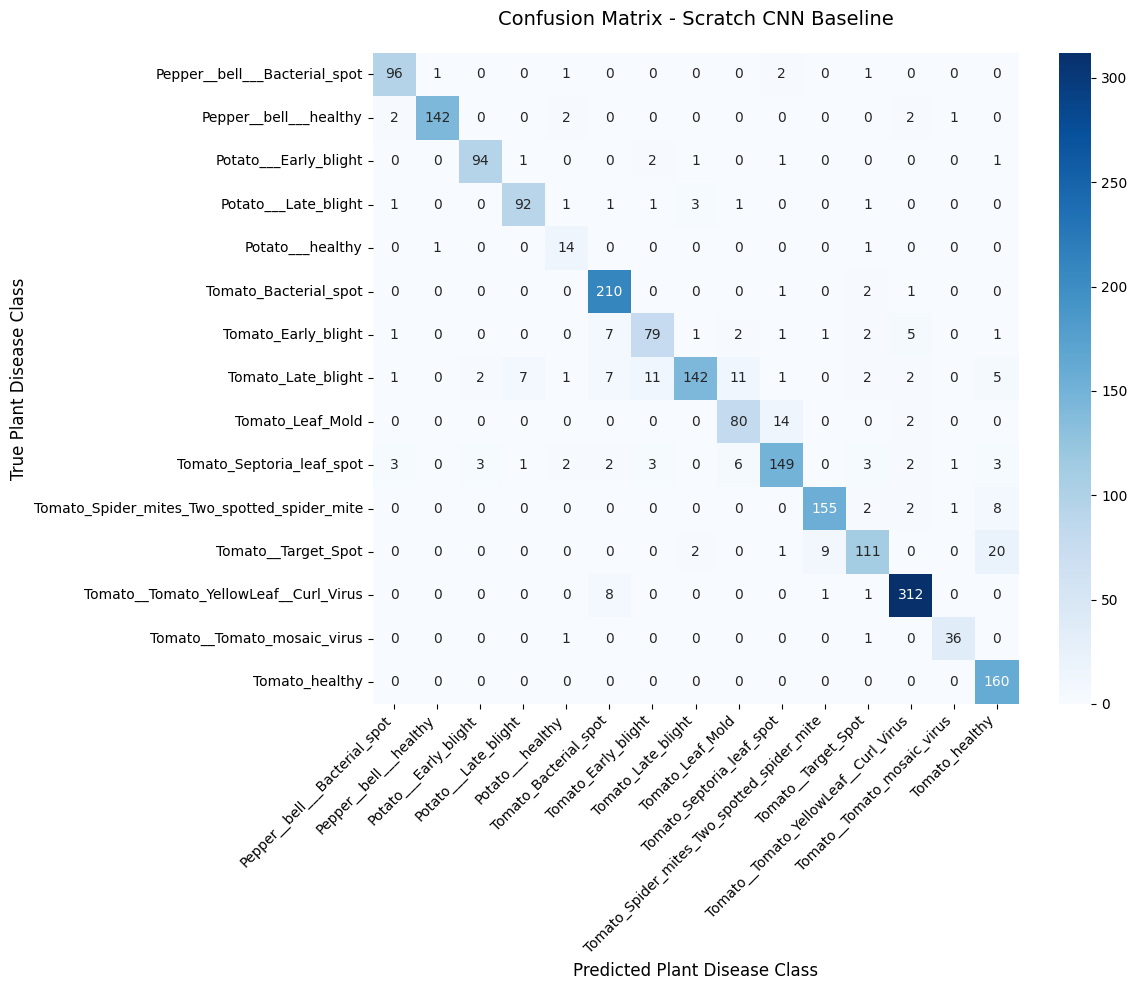

In [17]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

#get true labels and predictions from the test dataset
y_true = []
y_pred = []

print("Extracting predictions from the test dataset for the scratch model...")
for images, labels in test_ds:
    y_true.extend(labels.numpy())
    preds = model_scratch.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("\n" + "="*25 + " SCRATCH MODEL METRICS REPORT " + "="*25)
print(classification_report(y_true, y_pred, target_names=class_names))
print("="*80 + "\n")

#confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Scratch CNN Baseline', fontsize=14, pad=20)
plt.ylabel('True Plant Disease Class', fontsize=12)
plt.xlabel('Predicted Plant Disease Class', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
#optimization
import tensorflow as tf
from tensorflow.keras import layers, models

#load the pre-trained MobileNetV2 feature extractor from Google
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,      #exclude Google's final classification layer
    weights='imagenet'       #use the pre-trained ImageNet knowledge weights
)

#freeze the base model layers
base_model.trainable = False

#build the optimized CNN architecture stack
model_optimized = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_model,                       #transfer learning base
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),              #dropout(prevents overfitting)
    layers.BatchNormalization(),      #batch normalization(stabilizes training)
    layers.Dense(num_classes, activation='softmax')
])

#compile the optimized model with a fine-tuned learning rate
model_optimized.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#early stopping(cuts off training if validation loss stops improving)
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=4, restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'best_optimized_model.h5', monitor='val_accuracy', save_best_only=True
)

#print structural breakdown
model_optimized.summary()

#train the optimized model
print("Starting training for the highly optimized Transfer Learning model...")
history_optimized = model_optimized.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop, checkpoint]
)

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,282,319 (8.71 MB)

 Trainable params: 21,775 (85.06 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

...

452/452 ━━━━━━━━━━━━━━━━━━━━ 172s 381ms/step - accuracy: 0.8232 - loss: 0.5410 - val_accuracy: 0.8536 - val_loss: 0.4537
Epoch 12/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 371ms/step - accuracy: 0.8322 - loss: 0.5131

452/452 ━━━━━━━━━━━━━━━━━━━━ 174s 384ms/step - accuracy: 0.8279 - loss: 0.5259 - val_accuracy: 0.8587 - val_loss: 0.4407
Epoch 13/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 0.8310 - loss: 0.4970

452/452 ━━━━━━━━━━━━━━━━━━━━ 174s 384ms/step - accuracy: 0.8287 - loss: 0.5138 - val_accuracy: 0.8633 - val_loss: 0.4315
Epoch 14/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 0.8361 - loss: 0.4909

452/452 ━━━━━━━━━━━━━━━━━━━━ 174s 385ms/step - accuracy: 0.8319 - loss: 0.5028 - val_accuracy: 0.8662 - val_loss: 0.4222
Epoch 15/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step - accuracy: 0.8423 - loss: 0.4713

452/452 ━━━━━━━━━━━━━━━━━━━━ 172s 381ms/step - accuracy: 0.8406 - loss: 0.4777 - val_accuracy: 0.8710 - val_loss: 0.4108


Extracting test predictions for the OPTIMIZED model...

========================= OPTIMIZED MODEL METRICS REPORT =========================
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.89      0.95      0.92       101
                     Pepper__bell___healthy       0.97      0.97      0.97       149
                      Potato___Early_blight       0.97      1.00      0.99       100
                       Potato___Late_blight       0.95      0.92      0.93       101
                           Potato___healthy       0.94      0.94      0.94        16
                      Tomato_Bacterial_spot       0.81      0.95      0.88       214
                        Tomato_Early_blight       0.77      0.43      0.55       100
                         Tomato_Late_blight       0.91      0.86      0.89       192
                           Tomato_Leaf_Mold       0.72      0.93      0.81        96
          

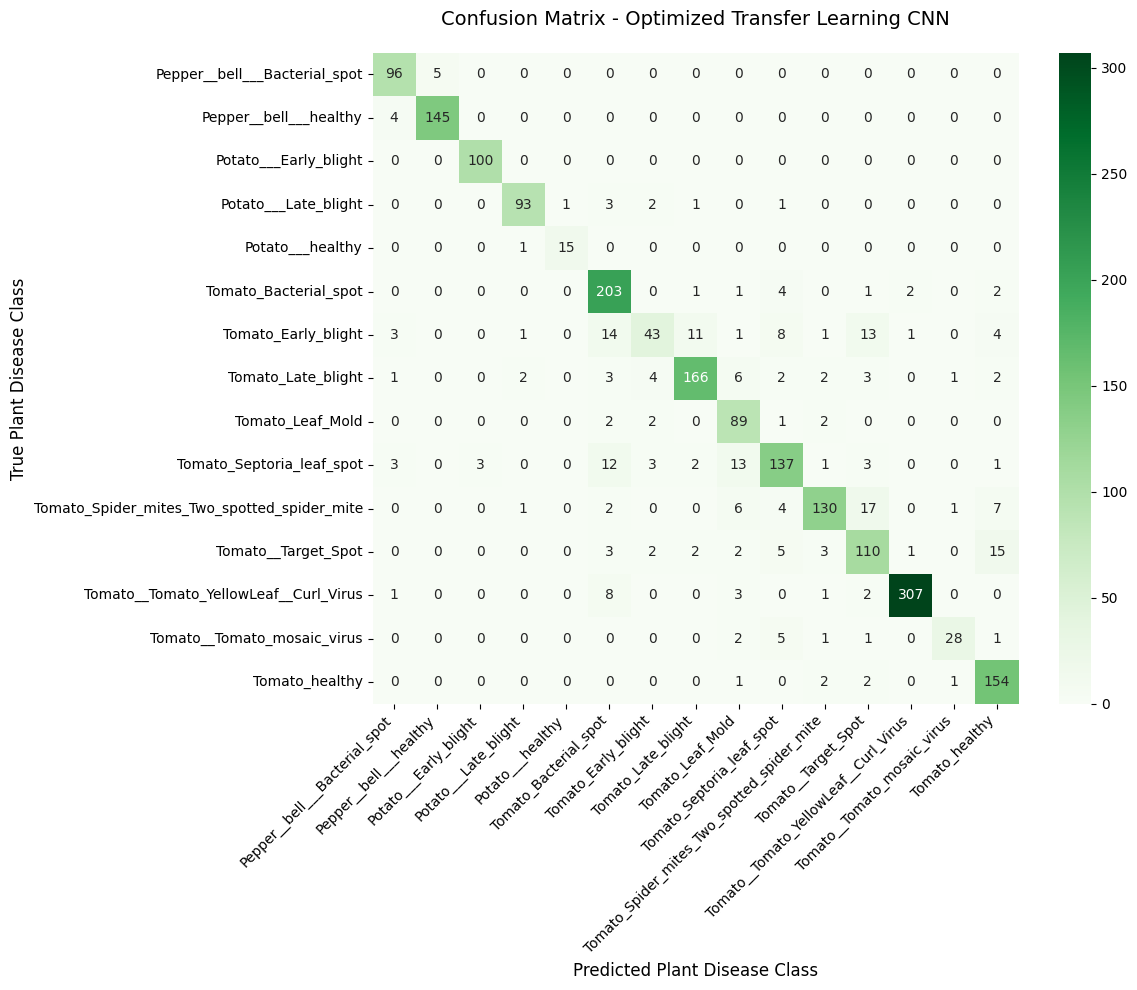

In [19]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

#get true labels and predictions from the Test Dataset for the optimized model
y_true_opt = []
y_pred_opt = []

print("Extracting test predictions for the OPTIMIZED model...")
for images, labels in test_ds:
    y_true_opt.extend(labels.numpy())
    preds = model_optimized.predict(images, verbose=0)
    y_pred_opt.extend(np.argmax(preds, axis=1))

y_true_opt = np.array(y_true_opt)
y_pred_opt = np.array(y_pred_opt)

print("\n" + "="*25 + " OPTIMIZED MODEL METRICS REPORT " + "="*25)
print(classification_report(y_true_opt, y_pred_opt, target_names=class_names))
print("="*82 + "\n")

#plot confusion matrix
cm_opt = confusion_matrix(y_true_opt, y_pred_opt)

plt.figure(figsize=(12, 10))
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Greens', # Green theme to separate from scratch model
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Optimized Transfer Learning CNN', fontsize=14, pad=20)
plt.ylabel('True Plant Disease Class', fontsize=12)
plt.xlabel('Predicted Plant Disease Class', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


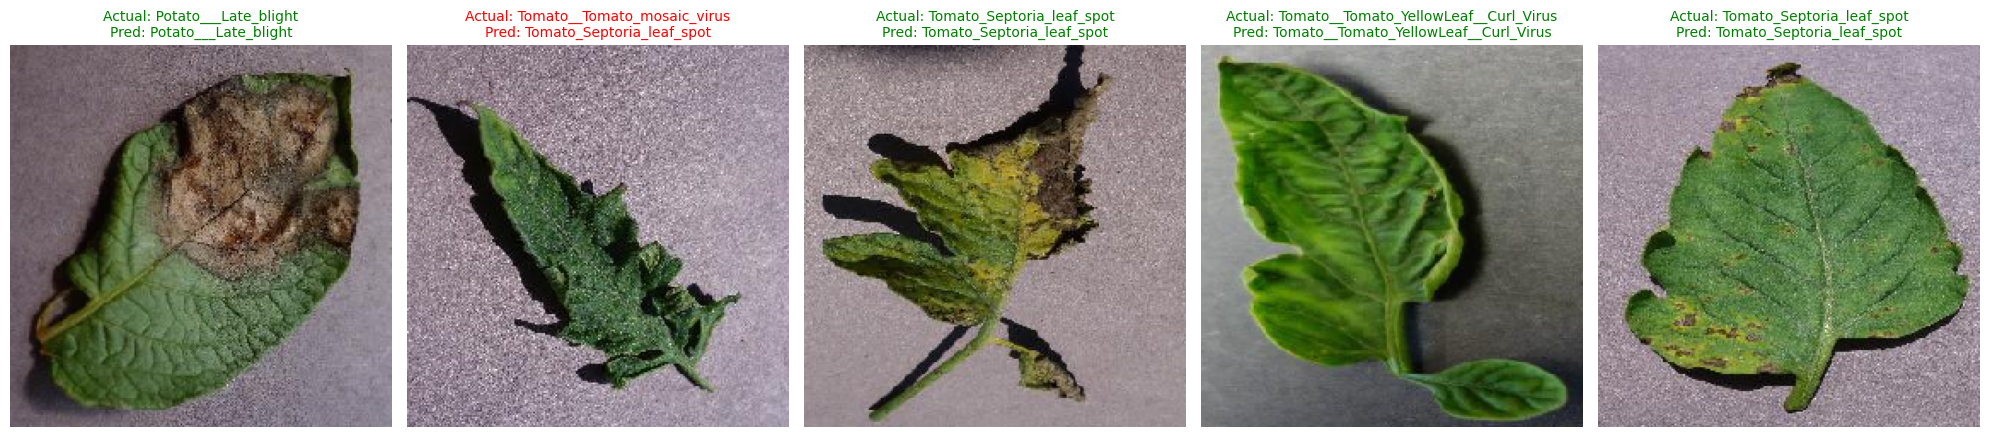

In [20]:
#path to the test directory folders
test_dir = output_dir + "/test"

#show 5 sample images side-by-side
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

images_processed = 0

while images_processed < 5:
    #pick a random class folder
    random_class = random.choice(class_names)
    class_path = os.path.join(test_dir, random_class)

    #pick a random image file from that folder
    if not os.path.exists(class_path) or len(os.listdir(class_path)) == 0:
        continue
    random_img_name = random.choice(os.listdir(class_path))
    img_path = os.path.join(class_path, random_img_name)

    #load and preprocess the image
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.utils.img_to_array(img)
    img_array = img_array / 255.0  #normalize
    img_batch = np.expand_dims(img_array, axis=0)

    #run prediction using the optimized model
    predictions = model_optimized.predict(img_batch, verbose=0)
    predicted_class_idx = np.argmax(predictions[0])
    predicted_class_name = class_names[predicted_class_idx]

    #text color: green if correct, red if wrong
    color = 'green' if predicted_class_name == random_class else 'red'

    #display the image
    axes[images_processed].imshow(img)
    axes[images_processed].set_title(
        f"Actual: {random_class}\nPred: {predicted_class_name}",
        color=color,
        fontsize=10
    )
    axes[images_processed].axis('off')

    images_processed += 1

plt.tight_layout()
plt.show()

In [21]:
#model saving & deployment

#save model in native Keras format
model_optimized.save('plant_disease_model.keras')
print("Successfully saved model as 'plant_disease_model.keras'!")

#convert trained model into the lightweight TensorFlow Lite (.tflite) format
converter = tf.lite.TFLiteConverter.from_keras_model(model_optimized)
tflite_model = converter.convert()

#save the converted TFLite file to disk
tflite_file_path = 'plant_disease_model.tflite'
with open(tflite_file_path, 'wb') as f:
    f.write(tflite_model)

print("Successfully converted and saved model as 'plant_disease_model.tflite'!")


Successfully saved model as 'plant_disease_model.keras'!
Saved artifact at '/tmp/tmpnft1yhe8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_340')
Output Type:
  TensorSpec(shape=(None, 15), dtype=tf.float32, name=None)
Captures:
  134897413392144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134897413391376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134897413391184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134897413394064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134897413391952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134897413391568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134897413393296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134897413393872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134897413393488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134897413398864: Tenso

Found 23 images


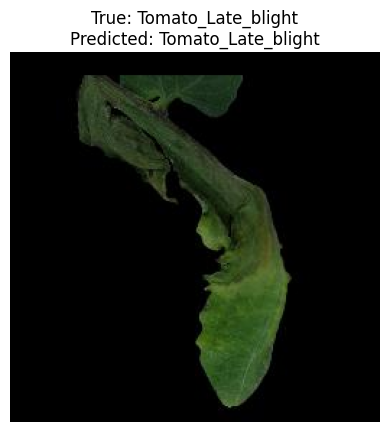

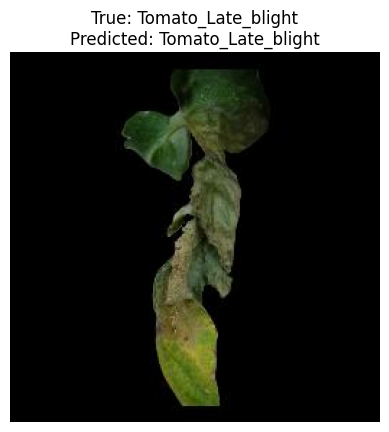

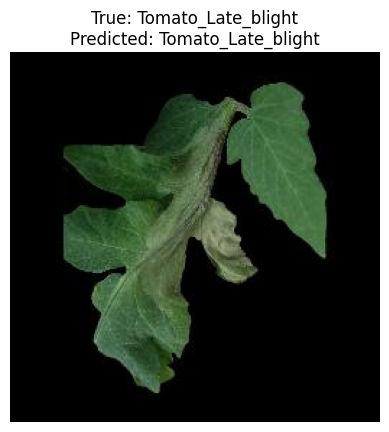

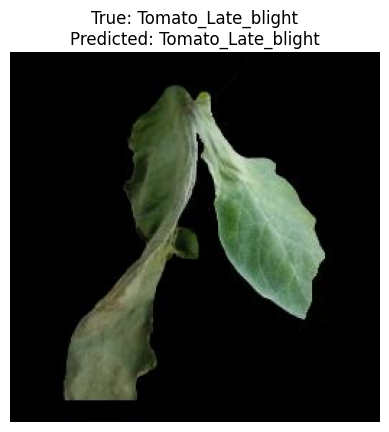

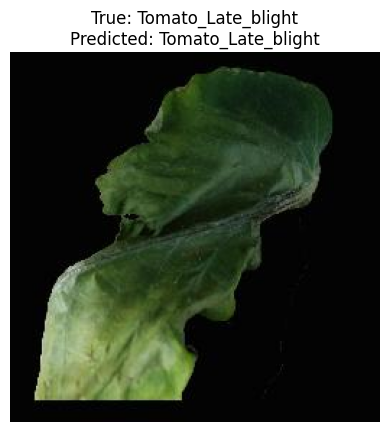

In [28]:
import glob, random
import matplotlib.pyplot as plt
import os

#collect all test images
test_images = glob.glob("/content/plantvillage_split/test/*/*.jpg")
print("Found", len(test_images), "images")

#pick 5 random images
sample_imgs = random.sample(test_images, 5)

#display each image with true + predicted labels
for img_path in sample_imgs:
    #true label is the folder name
    true_label = os.path.basename(os.path.dirname(img_path))

    #run prediction
    pred_label = predict_tflite(img_path)

    #show image
    img = Image.open(img_path)
    plt.imshow(img)
    plt.title(f"True: {true_label}\nPredicted: {pred_label}")
    plt.axis("off")
    plt.show()